In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from matplotlib import patches as mpatches
from hyperparameter_search import HYPERPARAMETER_GROUPS
from utils import AUX_HEAD_KEYS
from tqdm import tqdm
import math
import numpy as np
from scipy import stats
from scipy.stats import false_discovery_control, ttest_ind

/Users/jacquesamsel/.pyenv/versions/skripsie2/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
data = pd.read_csv("results/aux_head_regression_scores.csv")
data = data[data["model_name"] != "test_pc_grad"]
data["run_number"] = data["model_name"].str[-1].astype(int)
data["model_name"] = data["model_name"].str[:-3]
data["aux_weight"] = data["model_name"].str.extract(r"_w([\d\.]+)$").astype(float)
data["model_name"] = data["model_name"].str.replace(r"_w[\d\.]+$", "", regex=True)
data["readable_name"] = data["model_name"] + data["aux_weight"].map(lambda x: f" Weight={x}" if x > 0 else "")
data

,model_name,target,iteration,r2_score,mae,target_stddev,run_number,aux_weight,readable_name
0,velocity_forward,velocity_forward,0,0.513926,0.208804,0.655941,4,1.0,velocity_forward Weight=1.0
1,velocity_forward,velocity_lateral,0,0.958851,0.014317,0.101544,4,1.0,velocity_forward Weight=1.0
2,velocity_forward,angular_velocity_y,0,0.952726,0.144078,0.958185,4,1.0,velocity_forward Weight=1.0
3,velocity_forward,track_curvature_0_50,0,0.253044,0.310509,0.533184,4,1.0,velocity_forward Weight=1.0
4,velocity_forward,track_curvature_1_00,0,0.290707,0.311563,0.547542,4,1.0,velocity_forward Weight=1.0
...,...,...,...,...,...,...,...,...,...
188239,angular_velocity_y,wheel_slip_lateral_front_right,600,0.893928,0.004809,0.021193,1,0.1,angular_velocity_y Weight=0.1
188240,angular_velocity_y,wheel_slip_forward_back_left,600,0.324005,0.047011,0.116064,1,0.1,angular_velocity_y Weight=0.1
188241,angular_velocity_y,wheel_slip_forward_back_right,600,0.288497,0.048209,0.116956,1,0.1,angular_velocity_y Weight=0.1
188242,angular_velocity_y,wheel_slip_lateral_back_left,600,0.858701,0.001710,0.007818,1,0.1,angular_velocity_y Weight=0.1


In [3]:
data[data["model_name"].isin(["baseline", "rnn_baseline"]) & data["iteration"].isin([0, 600])]\
    .pivot_table(columns=["model_name", "iteration"], index="target", aggfunc="mean", values="r2_score").loc[AUX_HEAD_KEYS].to_csv("results/baseline_r2_scores.csv")

/var/folders/tf/2rc426jn0wdfbl876c7ypg1h0000gn/T/ipykernel_39511/3733721124.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
/var/folders/tf/2rc426jn0wdfbl876c7ypg1h0000gn/T/ipykernel_39511/3733721124.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")


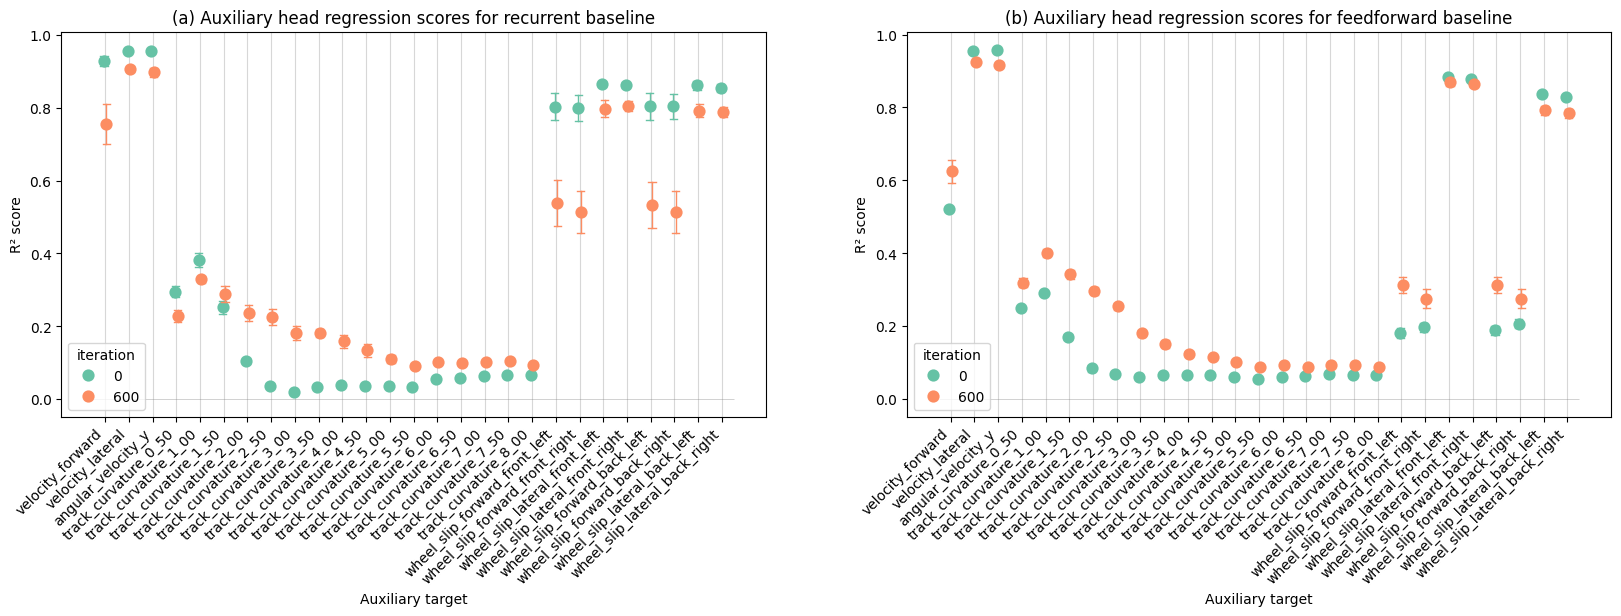

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(20, 5))

for ax, model_name, letter in zip(axs, ["rnn_baseline", "baseline"], ['a', 'b']):
    raw = data[(data["model_name"] == model_name) & (data["iteration"].isin([0, 600]))]

    sns.pointplot(
        data=raw, 
        x="target", 
        y="r2_score", 
        hue="iteration",
        order=AUX_HEAD_KEYS,
        errorbar="se",
        dodge=0.1,
        linestyle="none",
        palette="Set2",
        capsize=0.3,
        err_kws={"linewidth": 1},
        ax=ax
    ).set(xlabel="Auxiliary target", ylabel="R² score", title=f"({letter}) Auxiliary head regression scores for {'recurrent baseline' if model_name == 'rnn_baseline' else 'feedforward baseline'}")
    ax.grid(axis="x", alpha=0.5)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.hlines(y=0, xmin=-0.5, xmax=len(AUX_HEAD_KEYS)-0.5, colors="gray" ,alpha=0.5, lw=0.5)

plt.savefig("results/figures/probe_dumbbell.pdf", bbox_inches="tight")

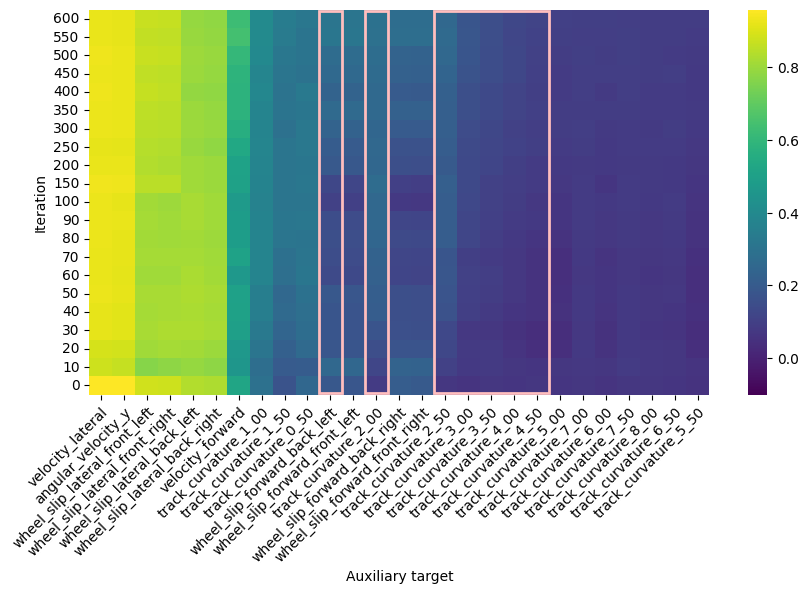

In [5]:
to_show = data[data["model_name"] == "baseline"].pivot_table(index="iteration", columns="target", values="r2_score")[::-1]
to_show = to_show[to_show.columns[to_show.loc[600].argsort()][::-1]]
plt.figure(figsize=(10, 5))
ax = sns.heatmap(to_show, cmap="viridis", vmin=-0.1)
ax.set(xlabel="Auxiliary target", ylabel="Iteration")

rect1 = mpatches.Rectangle((15, 0.1), 5, 20.8,
                          linewidth=2, edgecolor="#ffbebe", facecolor='none')
rect2 = mpatches.Rectangle((10, 0.1), 1, 20.8,
                          linewidth=2, edgecolor='#ffbebe', facecolor='none')
rect3 = mpatches.Rectangle((12, 0.1), 1, 20.8,
                          linewidth=2, edgecolor='#ffbebe', facecolor='none')
ax.add_patch(rect1)
ax.add_patch(rect2)
ax.add_patch(rect3)

plt.xticks(rotation=45, ha="right", rotation_mode="anchor")
plt.savefig("results/figures/probe_heatmap.pdf", bbox_inches="tight")

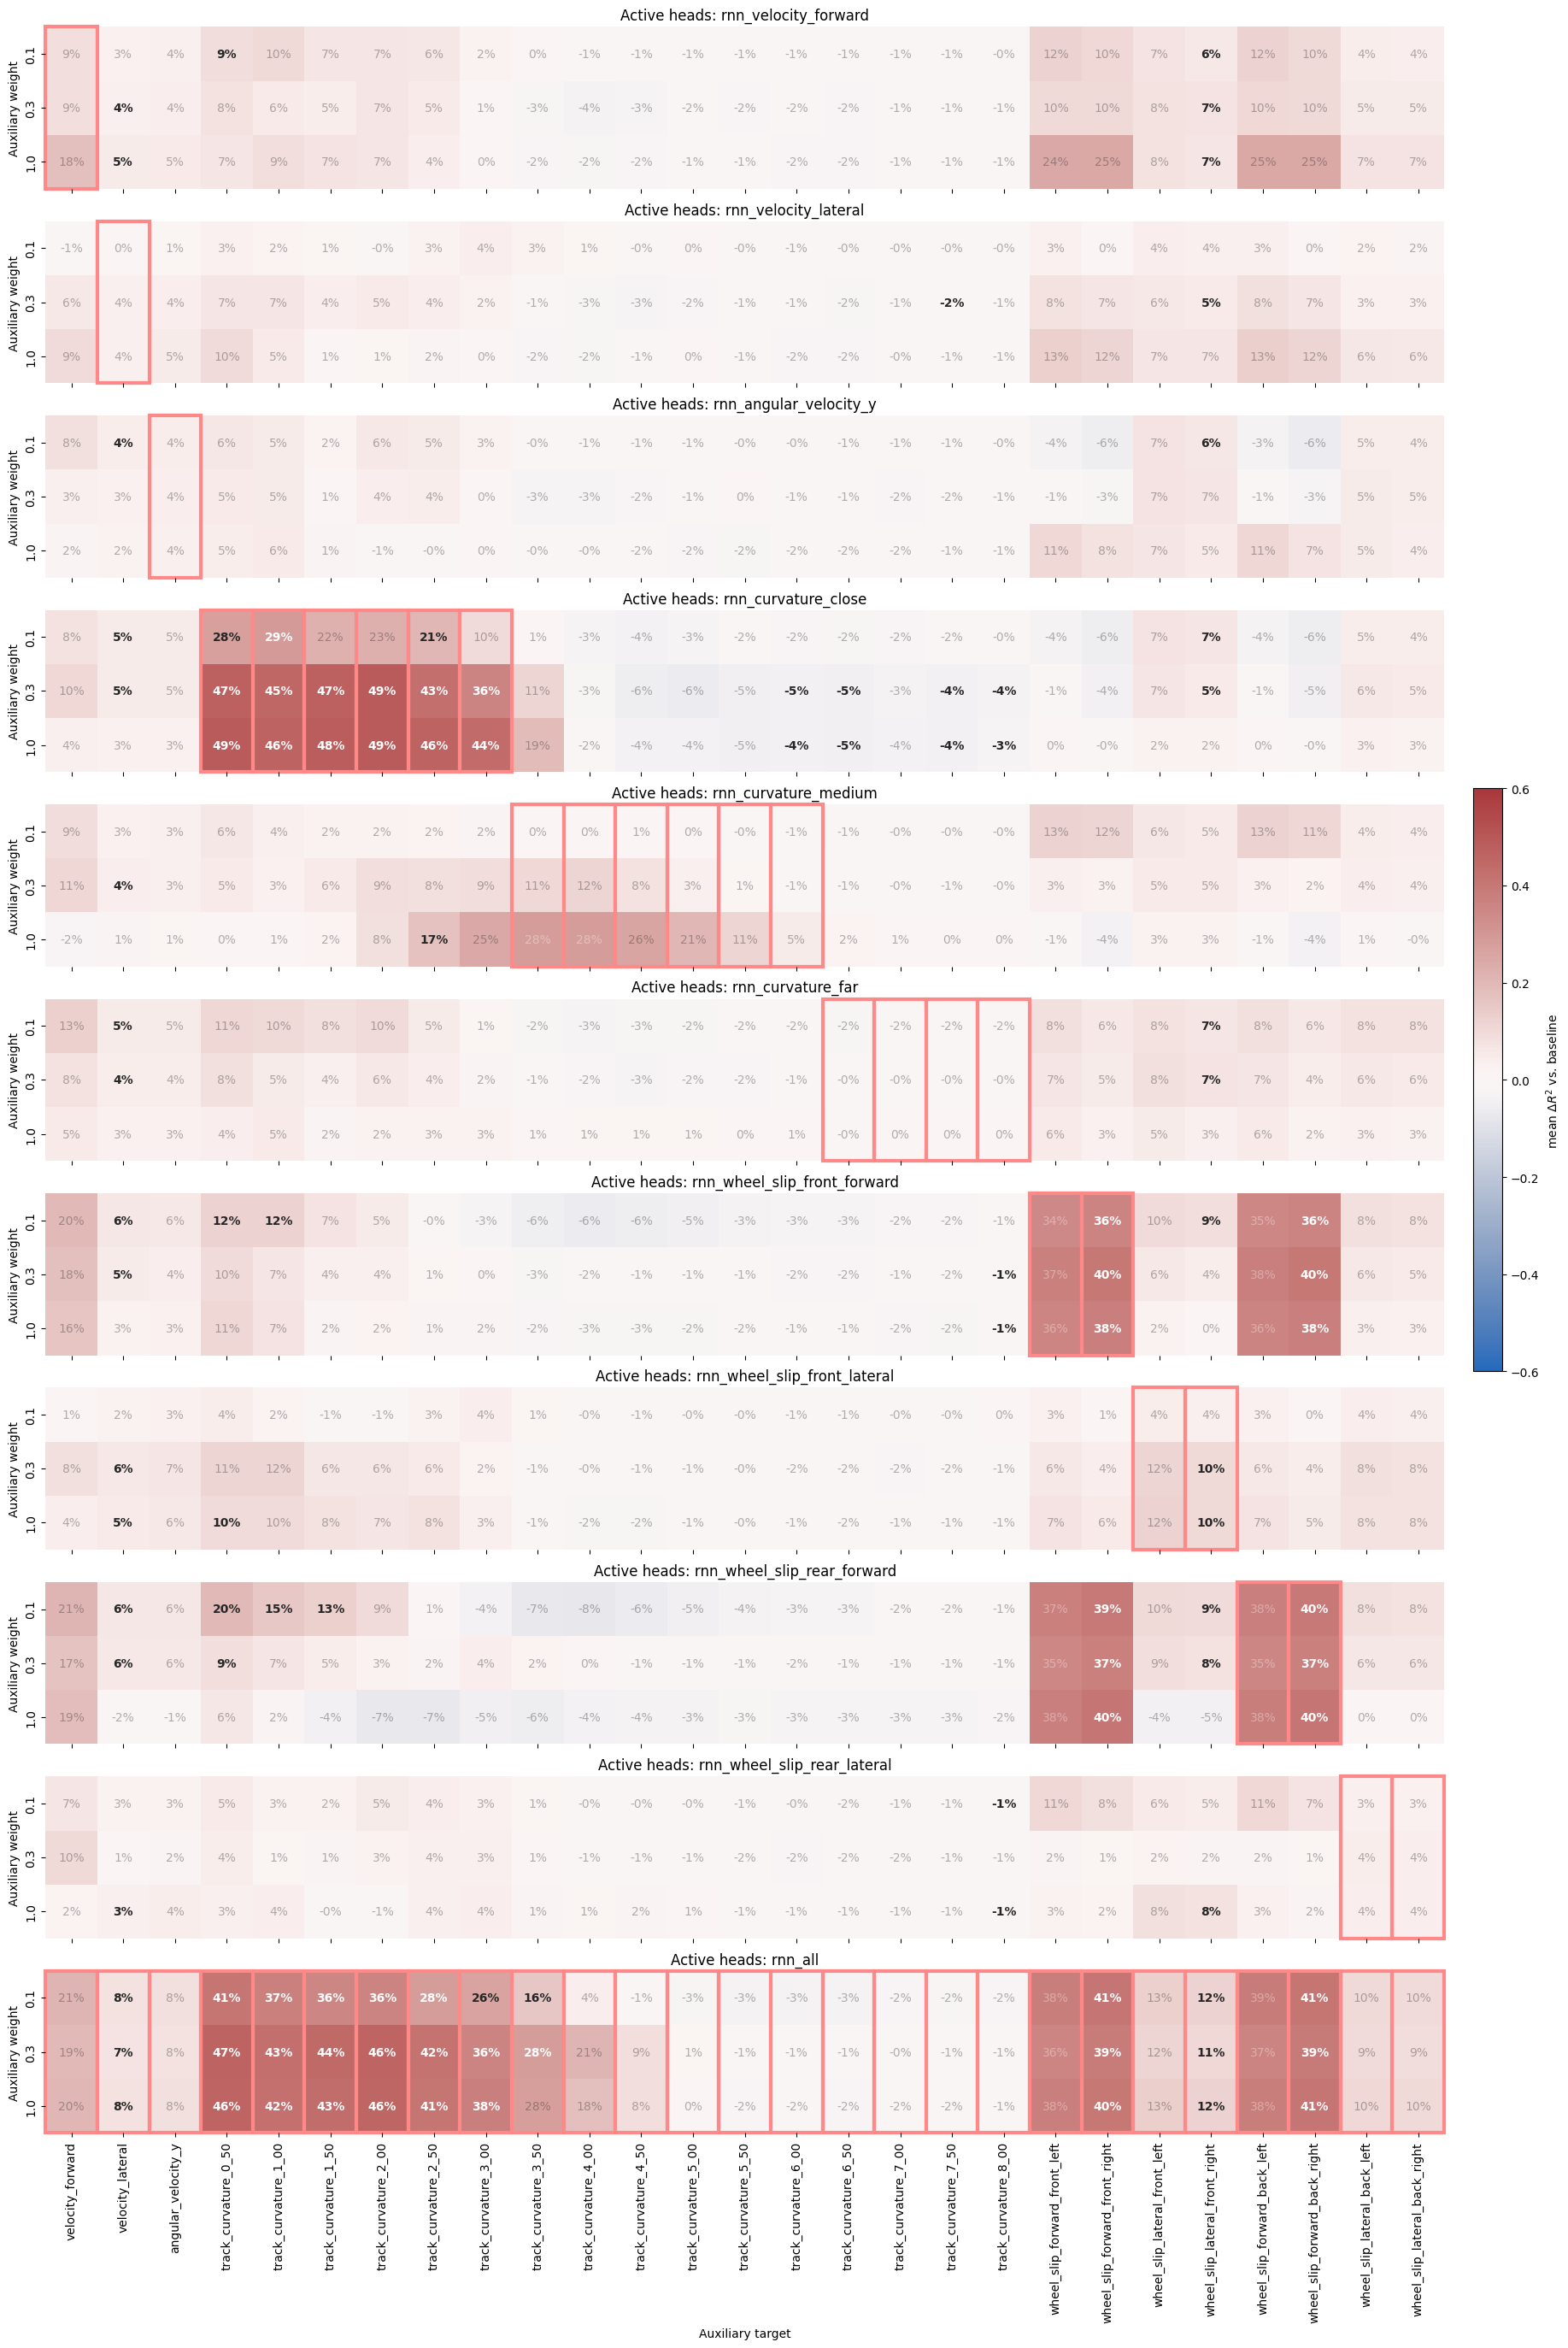

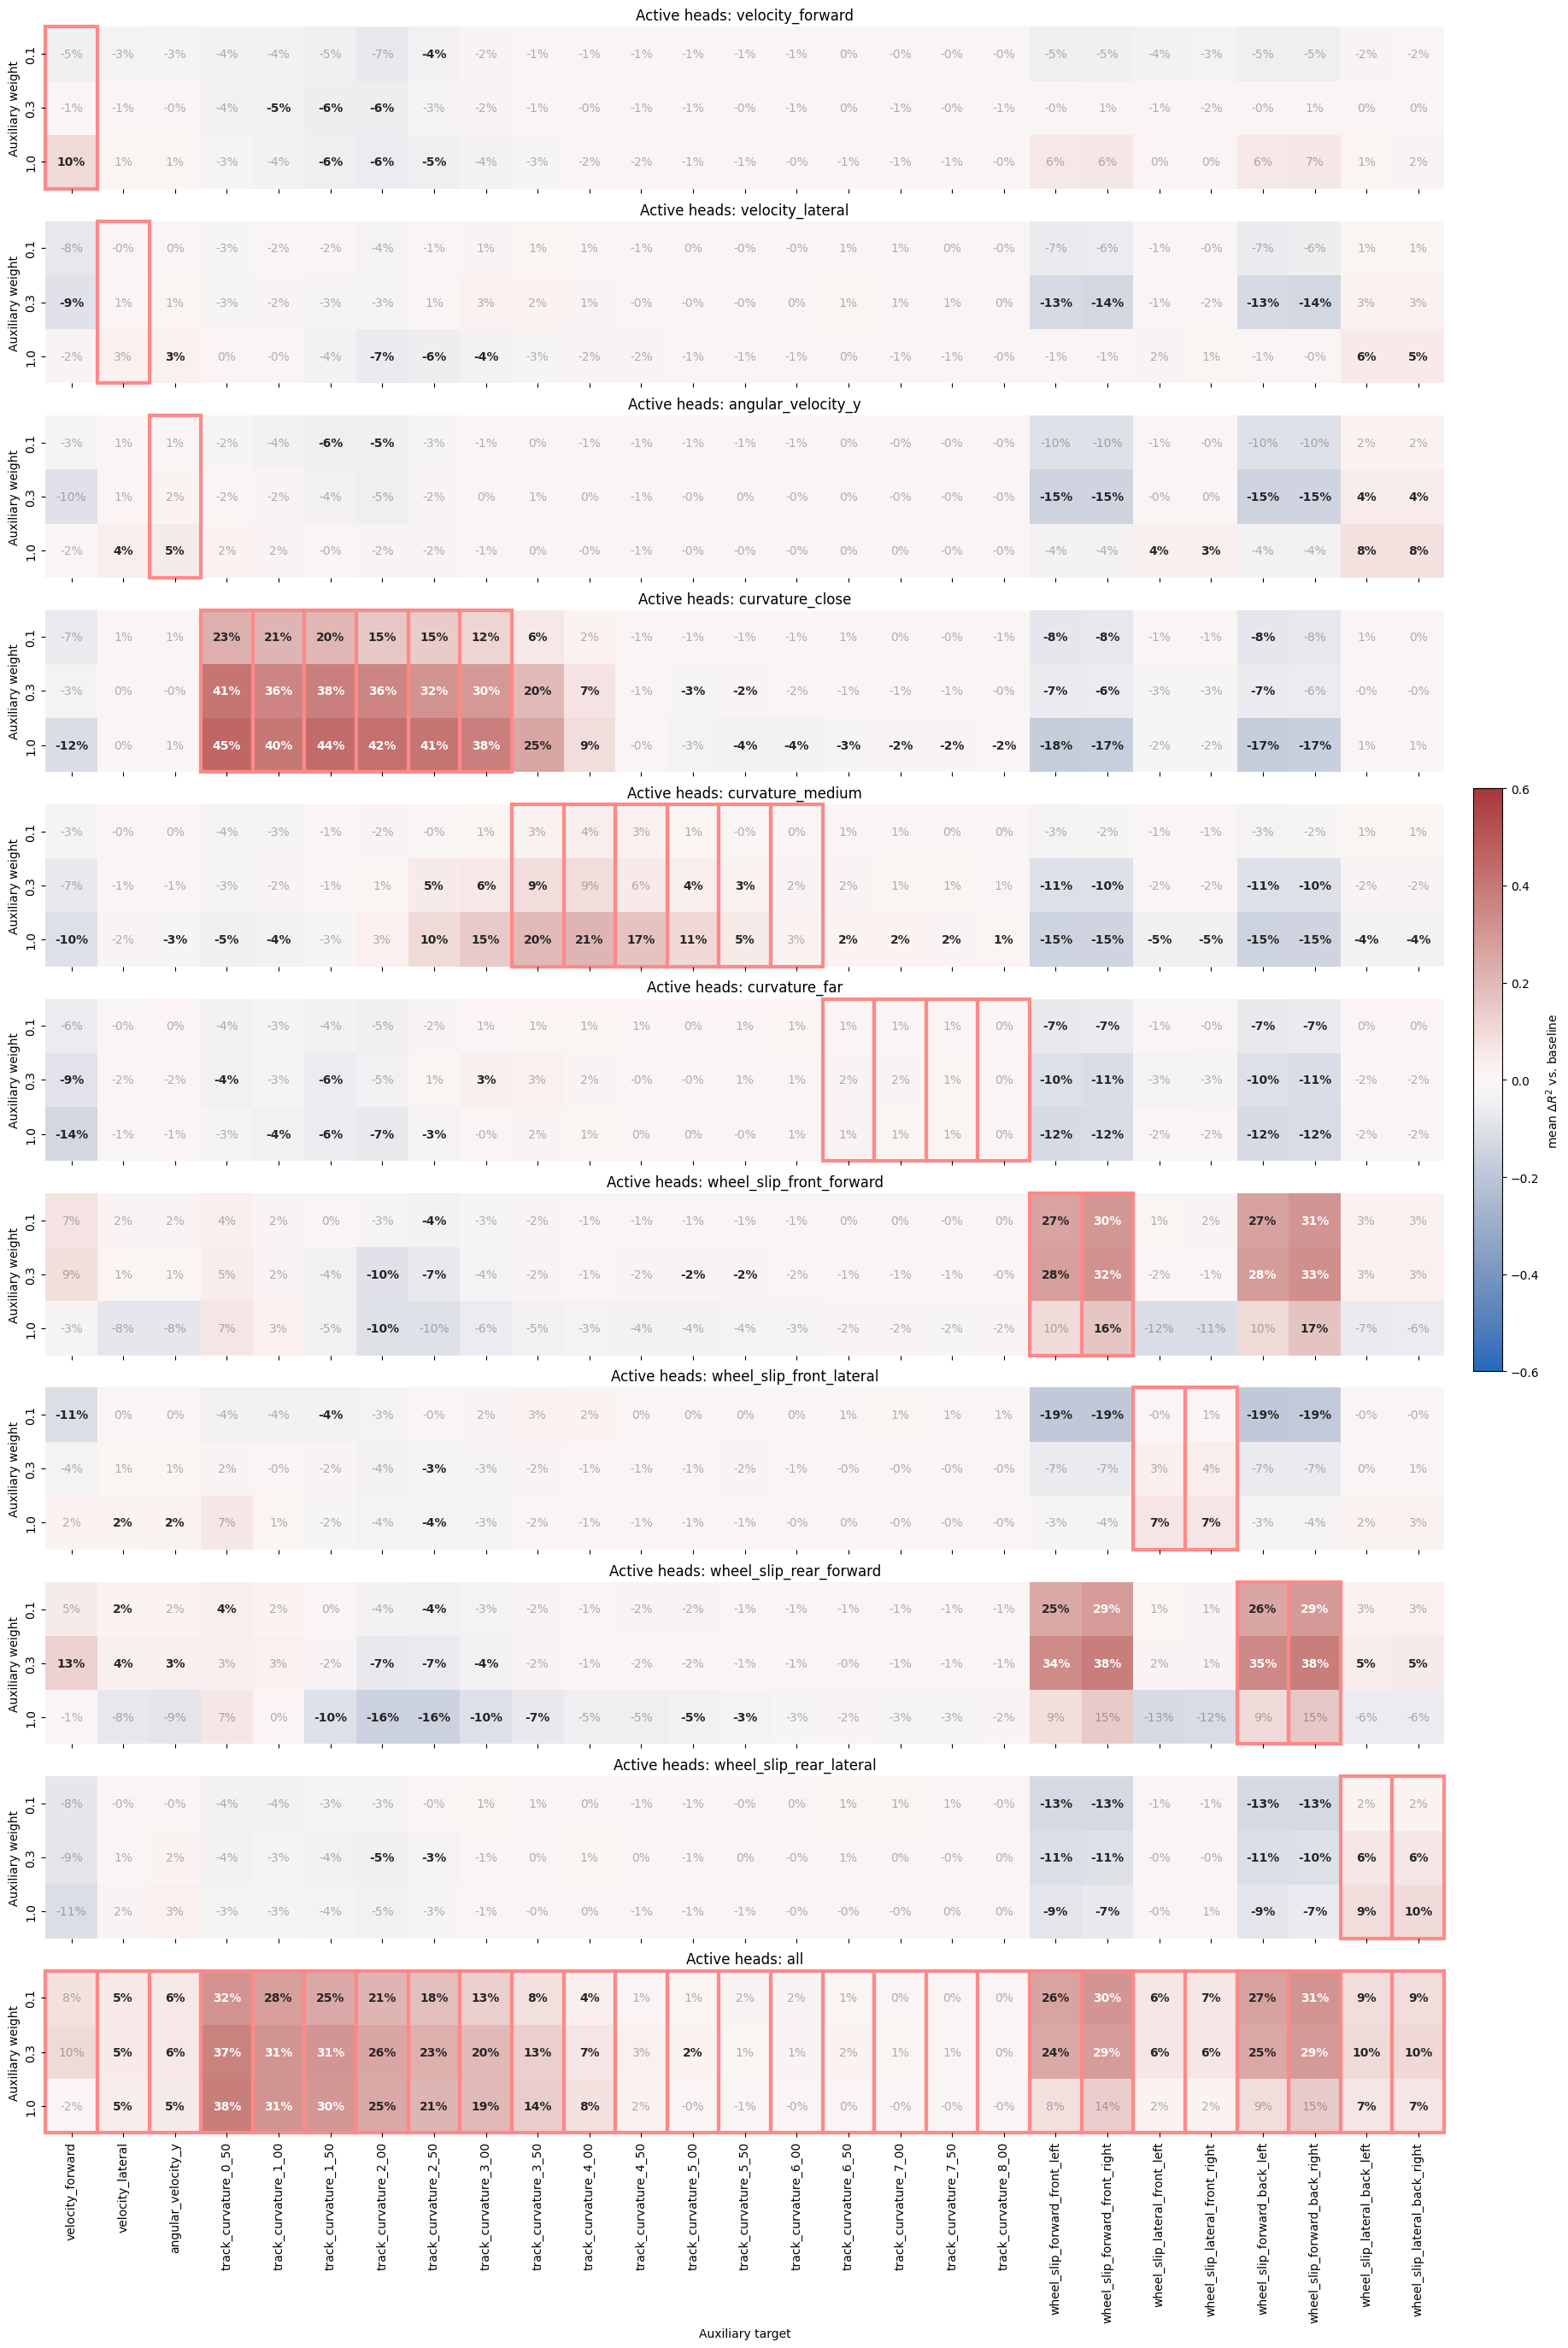

In [23]:
for model_kind in ["recurrent", "feedforward"]:
    last_iteration_r2_scores = data[(data["iteration"] == 600) & (data["model_name"].str.startswith("rnn_") if model_kind == "recurrent" else True)].pivot(index=["model_name", "aux_weight", "run_number"], columns="target", values="r2_score")[AUX_HEAD_KEYS]
    baseline_name = "rnn_baseline" if model_kind == "recurrent" else "baseline"
    base = last_iteration_r2_scores.loc[baseline_name]

    last_iter_mean_r2_scores = last_iteration_r2_scores.groupby(level=["model_name", "aux_weight"]).mean()
    # do Welch t-test
    last_iter_ttest_results = last_iteration_r2_scores.drop(baseline_name).groupby(level=["model_name", "aux_weight"]).apply(
        lambda g: pd.DataFrame(ttest_ind(g, base, equal_var=False)[:2], index=["t", "p"], columns=AUX_HEAD_KEYS).T["p"]
    )

    # adjust for false discovery rate using Benjamini-Hochberg procedure
    last_iter_ttest_results = pd.DataFrame(false_discovery_control(last_iter_ttest_results), columns=last_iter_ttest_results.columns, index=last_iter_ttest_results.index)

    to_show = last_iter_mean_r2_scores.sub(last_iter_mean_r2_scores.loc[baseline_name].iloc[0], axis="columns").drop(baseline_name)

    fig, axs = plt.subplots(len(HYPERPARAMETER_GROUPS), 1, sharex="all", figsize=(22, 32))

    for model, ax in zip(HYPERPARAMETER_GROUPS.keys(), axs):
        hg_name = model
        model = model if model_kind == "feedforward" else f"rnn_{model}"
        sns.heatmap(to_show.loc[model], ax=ax, annot=True, fmt=".0%", cmap="vlag", cbar=False, vmin=-0.6, vmax=0.6)

        ax.set(title=f"Active heads: {model}",
            ylabel="Auxiliary weight", xlabel="")

        for txt, is_sig in zip(ax.texts, (last_iter_ttest_results.loc[model] < 0.1).to_numpy().ravel()):
            if not is_sig:
                txt.set_alpha(0.35)
            else:
                txt.set_fontweight("bold")

        for t in HYPERPARAMETER_GROUPS[hg_name]:
                if t in to_show.loc[model].columns:
                    c = to_show.loc[model].columns.get_loc(t)
                    ax.add_patch(mpatches.Rectangle((c, 0), 1, to_show.loc[model].shape[0], fill=False,
                                edgecolor="#ff8989", lw=3, clip_on=False))

    axs[-1].set_xlabel("Auxiliary target")
    fig.colorbar(axs[0].collections[0], ax=axs, location="right",
                label=r"mean $\Delta R^2$ vs. baseline",
                fraction=0.02, pad=0.02)

    fig.savefig("results/figures/probe_heatmap_aux.pdf" if model_kind == "feedforward" else "results/figures/probe_heatmap_aux_rnn.pdf", bbox_inches="tight")

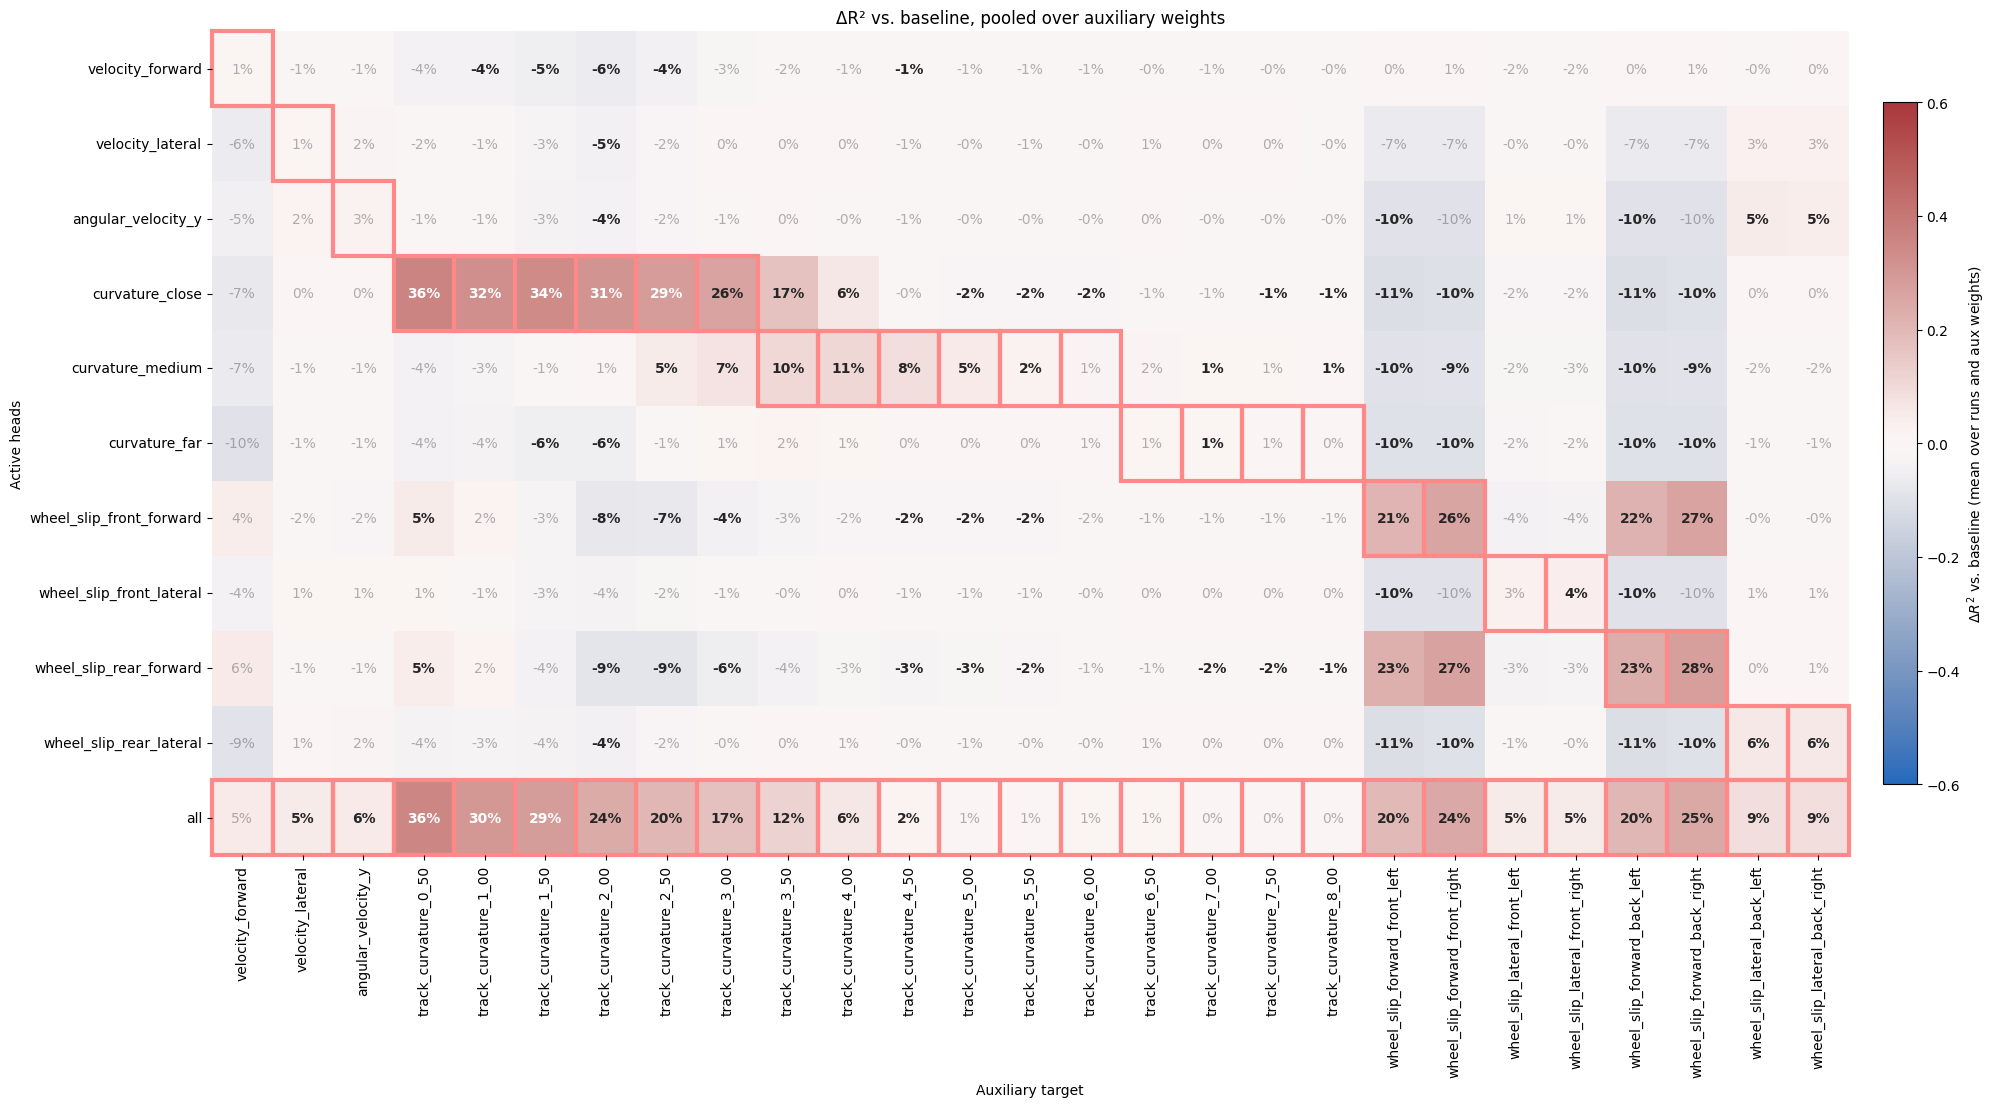

In [7]:
scores = (
    data[data["iteration"] == 600]
    .pivot(index=["model_name", "aux_weight", "run_number"], columns="target", values="r2_score")
    [AUX_HEAD_KEYS]
)
base = scores.loc["baseline"]

# pool all aux weights (and runs) per model
mean_r2 = scores.groupby(level="model_name").mean()

# Welch t-test per (model, target), all aux-weight runs pooled vs. baseline runs
pvals = scores.drop("baseline").groupby(level="model_name").apply(
    lambda g: pd.Series(ttest_ind(g, base, equal_var=False).pvalue, index=AUX_HEAD_KEYS)
)

# BH correction across the whole model x target grid
pvals = pd.DataFrame(
    false_discovery_control(pvals.to_numpy().ravel()).reshape(pvals.shape),
    index=pvals.index, columns=pvals.columns,
)

to_show = mean_r2.sub(mean_r2.loc["baseline"], axis="columns").drop("baseline")

# keep row order consistent with HYPERPARAMETER_GROUPS
row_order = [m for m in HYPERPARAMETER_GROUPS if m in to_show.index]
to_show = to_show.loc[row_order]
pvals = pvals.loc[row_order]

fig, ax = plt.subplots(figsize=(22, 0.7 * len(row_order) + 3))
sns.heatmap(to_show, ax=ax, annot=True, fmt=".0%", cmap="vlag", cbar=False, vmin=-0.6, vmax=0.6)

ax.set(title="ΔR² vs. baseline, pooled over auxiliary weights",
       xlabel="Auxiliary target", ylabel="Active heads")

# fade non-significant cells, bold significant ones (position-based, so NaN cells can't misalign)
sig = (pvals < 0.05).to_numpy()
for txt in ax.texts:
    x, y = txt.get_position()
    if sig[int(y), int(x)]:
        txt.set_fontweight("bold")
    else:
        txt.set_alpha(0.35)

# outline the cells for each model's active heads
for r, model in enumerate(row_order):
    for t in HYPERPARAMETER_GROUPS[model]:
        if t in to_show.columns:
            c = to_show.columns.get_loc(t)
            ax.add_patch(mpatches.Rectangle((c, r), 1, 1, fill=False,
                                            edgecolor="#ff8989", lw=3, clip_on=False))

fig.colorbar(ax.collections[0], ax=ax, location="right",
             label=r"$\Delta R^2$ vs. baseline (mean over runs and aux weights)",
             fraction=0.02, pad=0.02)

fig.savefig("results/figures/probe_heatmap_aux_pooled.pdf", bbox_inches="tight")

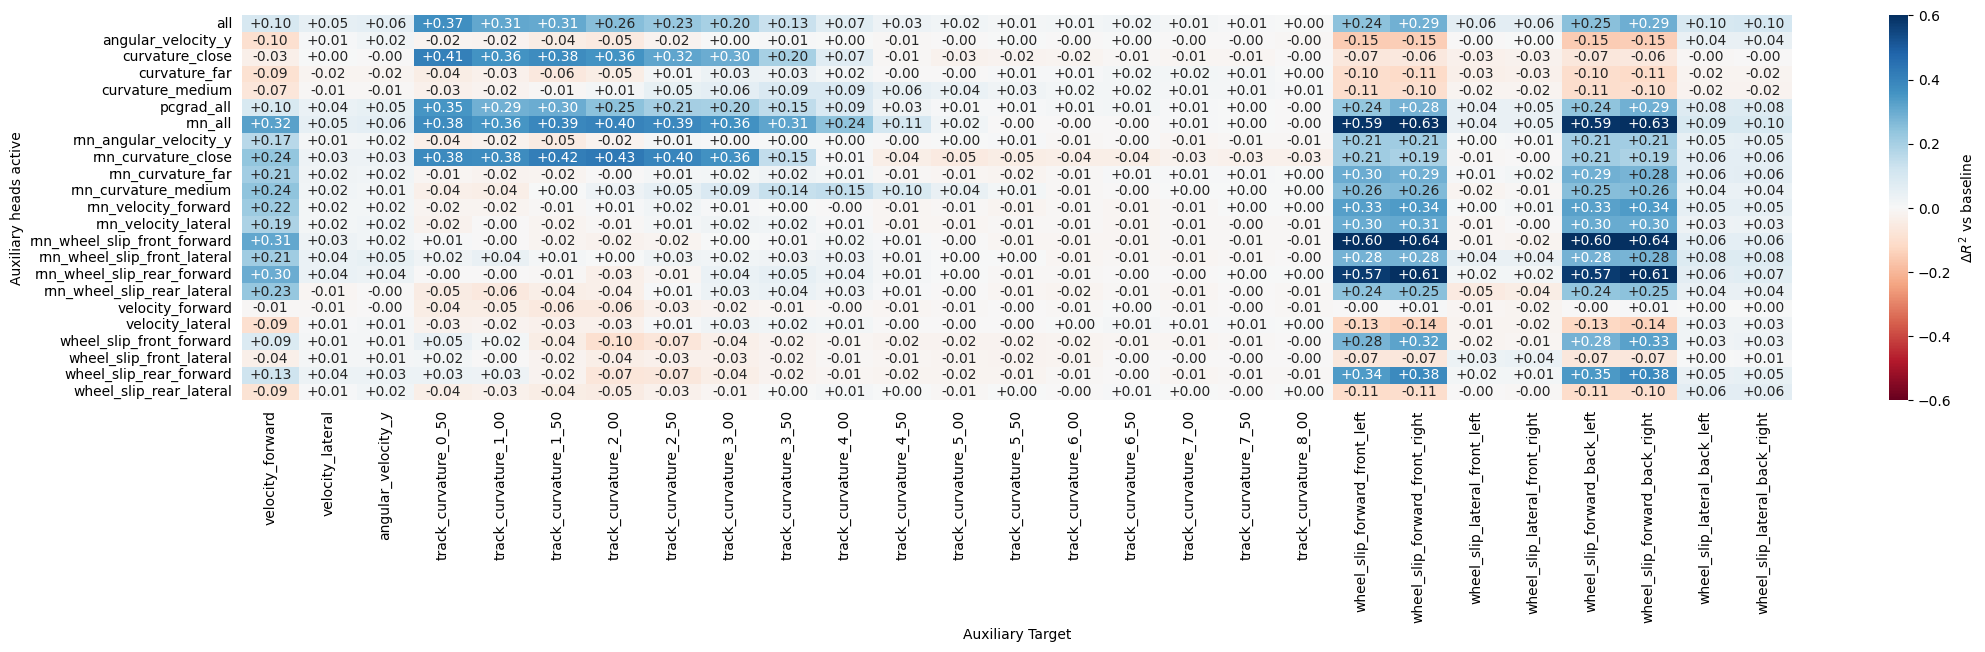

In [8]:
aux_weight = 0.3

pivot = (
    data[((data["aux_weight"] == aux_weight) | (data["model_name"] == "baseline"))
         & (data["iteration"] == 600)]
    .groupby(["model_name", "target"])["r2_score"]
    .mean()
    .unstack("target")
    .reindex(columns=AUX_HEAD_KEYS)
)

delta = pivot.sub(pivot.loc["baseline"], axis="columns").drop(index="baseline")

plt.figure(figsize=(25, 5))
heatmap = sns.heatmap(
    delta,
    cmap="RdBu",
    center=0,
    vmin=-0.6, vmax=0.6,
    cbar_kws={"label": r"$\Delta R^2$ vs baseline"},
    annot=True,
    fmt="+.2f"
)


heatmap.tick_params(left=False, bottom=False)
heatmap.set(xlabel="Auxiliary Target", ylabel="Auxiliary heads active")
plt.savefig("results/figures/probe_heatmap_delta_vs_baseline.pdf", bbox_inches='tight')


In [9]:
pivot.sub(pivot.loc["baseline"]).loc["curvature_close"]

target
velocity_forward                 -0.033633
velocity_lateral                  0.004275
angular_velocity_y               -0.000591
track_curvature_0_50              0.412155
track_curvature_1_00              0.360215
track_curvature_1_50              0.377615
track_curvature_2_00              0.358017
track_curvature_2_50              0.316467
track_curvature_3_00              0.296085
track_curvature_3_50              0.201181
track_curvature_4_00              0.074527
track_curvature_4_50             -0.005964
track_curvature_5_00             -0.025215
track_curvature_5_50             -0.021068
track_curvature_6_00             -0.017509
track_curvature_6_50             -0.009284
track_curvature_7_00             -0.011924
track_curvature_7_50             -0.011162
track_curvature_8_00             -0.003629
wheel_slip_forward_front_left    -0.069316
wheel_slip_forward_front_right   -0.062749
wheel_slip_lateral_front_left    -0.029589
wheel_slip_lateral_front_right   -0.026246
whee